# Smart IDS v3 — Notebook 05: Comprehensive Model Evaluation & Benchmarking
Multi-Model Comparison Table, Microsecond Latency, Normalized Confusion Matrices, and ROC/AUC

---

### What You Will Learn
1. **Real-Time Latency Benchmarking**: Measuring per-sample inference latency in microseconds with untimed warm-up runs.
2. **Side-by-Side Comparison**: Contrasting XGBoost, MLP, 1D-CNN (multi-class) with the Autoencoder (binary anomaly).
3. **Normalized Confusion Matrices**: Plotting a 2x2 grid showing conditional probabilities $P(\text{pred} \mid \text{true})$.
4. **One-vs-Rest ROC/AUC Curves**: Computing per-class and macro-averaged ROC curves.
5. **Persisting Results**: Saving `models/model_comparison.csv` and evaluation figures.

---

### Prerequisites
- Completion of Notebooks 01 through 04.
- All 4 models trained and saved in `models/`.


## 1. Security Concept: The Operational Latency Budget

> **Security Concept: Why does inference latency matter in network security?**
> A modern 10-Gigabit-per-second enterprise link processes over **1 million packets per second**.
> If an intrusion detection model takes 100 milliseconds to analyze a flow, incoming queues will instantly overflow, dropping packets and causing network downtime.
> In a production Intrusion Prevention System (IPS), models must evaluate flows within **microseconds** or small milliseconds.


In [1]:
import sys
from pathlib import Path

cur = Path.cwd()
root = cur if (cur / 'src').exists() else cur.parent
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import tensorflow as tf

from smart_ids.config import (
    CLASS_NAMES,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    SEED,
)
from smart_ids.artifacts import (
    load_all_artifacts,
    load_anomaly_threshold,
)
from smart_ids.evaluation import (
    measure_latency,
    compute_reconstruction_error,
    evaluate_supervised,
    evaluate_autoencoder_binary,
    plot_confusion_matrices,
    plot_roc_multiclass,
)

np.random.seed(SEED)
print("Evaluation environment initialized.")


Evaluation environment initialized.


## 2. Loading All Trained Models and Test Telemetry

We load all 4 saved models (MLP, 1D-CNN, XGBoost, Autoencoder) using `load_all_artifacts()`, along with the held-out test data.


In [2]:
artifacts = load_all_artifacts(MODELS_DIR)
print(f"Loaded artifacts: {list(artifacts.keys())}")

mlp_model = artifacts['MLP']
cnn_model = artifacts['CNN']
xgb_model = artifacts['XGBoost']
ae_model = artifacts['Autoencoder']
threshold_data = artifacts['threshold_data']
threshold = threshold_data['anomaly_threshold']

# Load test data
X_test_scaled = np.load(PROCESSED_DATA_DIR / 'X_test_scaled.npy')
y_test = np.load(PROCESSED_DATA_DIR / 'y_test.npy')
n_test = len(y_test)
print(f"Test dataset: {n_test:,} samples across {len(CLASS_NAMES)} classes.")


Loaded artifacts: ['MLP', 'CNN', 'Autoencoder', 'XGBoost', 'scaler', 'label_encoder', 'feature_names', 'threshold_data']
Test dataset: 3,750 samples across 8 classes.


## 3. Benchmarking Per-Sample Inference Latency ($\mu s$)

**What we do and why:**
We run 1 untimed warm-up call (to warm JIT compilers and cache lines), then measure the exact wall-clock time of 100 repeated single-sample predictions using Python's high-resolution `time.perf_counter()`.


In [3]:
latency_mlp = measure_latency(mlp_model, X_test_scaled, model_type='keras', n_runs=100)
latency_cnn = measure_latency(cnn_model, X_test_scaled, model_type='cnn', n_runs=100)
latency_xgb = measure_latency(xgb_model, X_test_scaled, model_type='xgboost', n_runs=100)
latency_ae  = measure_latency(ae_model,  X_test_scaled, model_type='ae', n_runs=100)

latency_df = pd.DataFrame({
    'Model': ['MLP (DNN)', '1D-CNN', 'XGBoost Baseline', 'Autoencoder (Zero-Day)'],
    'Latency (us)': [latency_mlp, latency_cnn, latency_xgb, latency_ae],
    'Throughput (flows/sec)': [1e6 / latency_mlp, 1e6 / latency_cnn, 1e6 / latency_xgb, 1e6 / latency_ae],
})
print("--- Inference Latency Benchmarks ---")
print(latency_df.round(2))


--- Inference Latency Benchmarks ---
                    Model  Latency (us)  Throughput (flows/sec)
0               MLP (DNN)      80535.88                   12.42
1                  1D-CNN      72334.99                   13.82
2        XGBoost Baseline        410.02                 2438.93
3  Autoencoder (Zero-Day)      45986.39                   21.75


## 4. Evaluating All Models & Building the Comparison Table

**What we do and why:**
We compute predictions on the test set for all 4 models:
- Supervised models: Weighted Precision, Recall, F1, and Accuracy.
- Autoencoder: Binary Precision, Recall, F1, and Accuracy against `(y_test != 0)`.
We consolidate these into `model_comparison.csv`.


In [4]:
# Predictions
# MLP
y_proba_mlp = mlp_model.predict(X_test_scaled, verbose=0)
y_pred_mlp = np.argmax(y_proba_mlp, axis=1)

# 1D-CNN
X_test_cnn = X_test_scaled.reshape(n_test, X_test_scaled.shape[1], 1)
y_proba_cnn = cnn_model.predict(X_test_cnn, verbose=0)
y_pred_cnn = np.argmax(y_proba_cnn, axis=1)

# XGBoost
y_proba_xgb = xgb_model.predict_proba(X_test_scaled)
y_pred_xgb = np.argmax(y_proba_xgb, axis=1)

# Autoencoder
test_errors = compute_reconstruction_error(ae_model, X_test_scaled)
y_pred_ae = (test_errors > threshold).astype(int)
y_true_binary = (y_test != 0).astype(int)

# Compute metrics
res_mlp = evaluate_supervised(y_test, y_pred_mlp, latency_us=latency_mlp)
res_cnn = evaluate_supervised(y_test, y_pred_cnn, latency_us=latency_cnn)
res_xgb = evaluate_supervised(y_test, y_pred_xgb, latency_us=latency_xgb)
res_ae  = evaluate_autoencoder_binary(y_true_binary, y_pred_ae, latency_us=latency_ae)

comparison_rows = [
    {'Model': 'MLP (DNN)', **res_mlp},
    {'Model': '1D-CNN', **res_cnn},
    {'Model': 'XGBoost Baseline', **res_xgb},
    {'Model': 'Autoencoder (Zero-Day)', **res_ae},
]
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(MODELS_DIR / 'model_comparison.csv', index=False)

print("--- Unified Model Comparison Table ---")
print(comparison_df.round(4))


--- Unified Model Comparison Table ---
                    Model  Accuracy  Precision  Recall  F1-Score  \
0               MLP (DNN)    0.8965     0.9061  0.8965    0.9008   
1                  1D-CNN    0.0357     0.0643  0.0357    0.0190   
2        XGBoost Baseline    0.9677     0.9694  0.9677    0.9681   
3  Autoencoder (Zero-Day)    0.8349     0.5201  0.2254    0.3145   

   Latency (us)                      Evaluation Type  
0     80535.878               Multi-class (Weighted)  
1     72334.990               Multi-class (Weighted)  
2       410.016               Multi-class (Weighted)  
3     45986.388  Binary (Zero-Day Anomaly vs Benign)  


## 5. Normalized Confusion Matrices (2x2 Grid)

**What we do and why:**
We plot row-normalized confusion matrices for all 4 models. Each cell shows the probability $P(\text{Predicted Class} \mid \text{True Class})$. Row normalization ensures rare attack classes are clearly visible despite class imbalance.


In [5]:
cms = {
    'MLP': confusion_matrix(y_test, y_pred_mlp),
    '1D-CNN': confusion_matrix(y_test, y_pred_cnn),
    'XGBoost': confusion_matrix(y_test, y_pred_xgb),
    'Autoencoder': confusion_matrix(y_true_binary, y_pred_ae),
}

fig_cm = plot_confusion_matrices(
    cms,
    class_names=CLASS_NAMES,
    save_path=MODELS_DIR / 'confusion_matrices.png',
)
plt.show()


<Figure size 1600x1400 with 8 Axes>

## 6. Receiver Operating Characteristic (ROC) & AUC Analysis

**What we do and why:**
We compute One-vs-Rest ROC curves with macro-average AUC for the multi-class models, and a direct ROC curve for the Autoencoder's continuous reconstruction error.


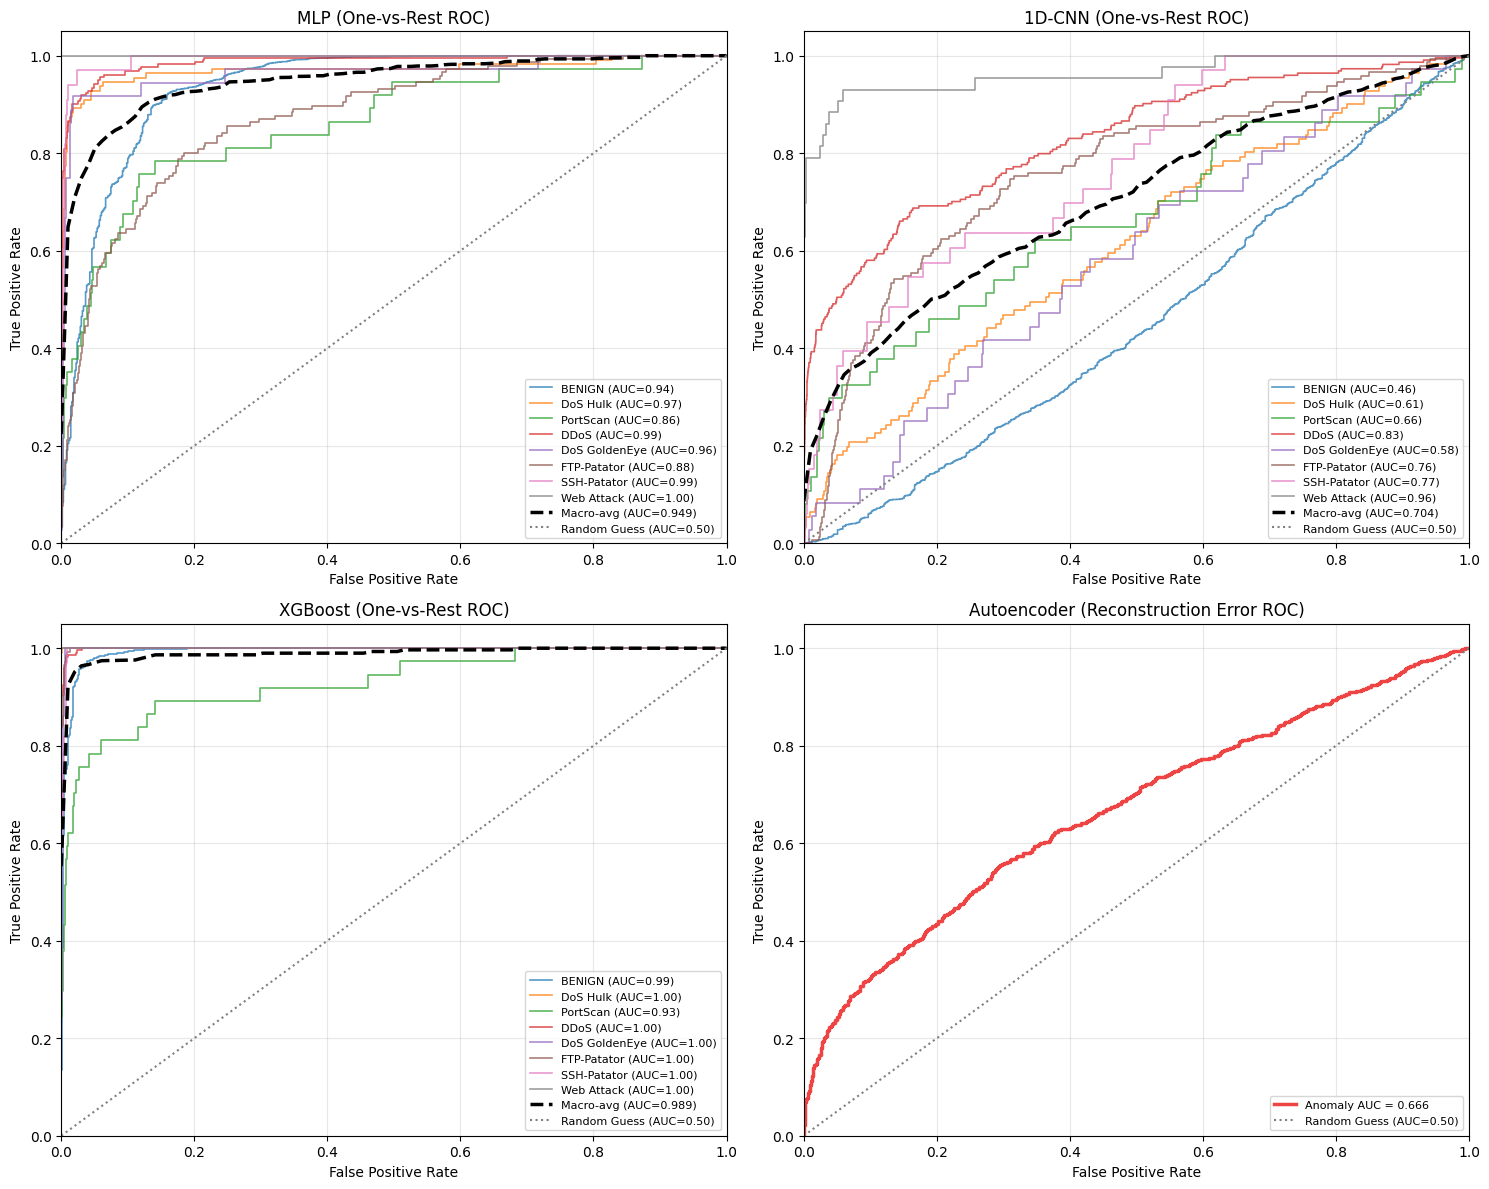

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

plot_roc_multiclass(y_test, y_proba_mlp, CLASS_NAMES, "MLP (One-vs-Rest ROC)", axes[0, 0])
plot_roc_multiclass(y_test, y_proba_cnn, CLASS_NAMES, "1D-CNN (One-vs-Rest ROC)", axes[0, 1])
plot_roc_multiclass(y_test, y_proba_xgb, CLASS_NAMES, "XGBoost (One-vs-Rest ROC)", axes[1, 0])
plot_roc_multiclass(y_true_binary, test_errors, ["Benign", "Attack"], "Autoencoder (Reconstruction Error ROC)", axes[1, 1], binary=True)

plt.tight_layout()
plt.savefig(MODELS_DIR / 'roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()


---
## Summary and Next Notebook

In this notebook:
- We benchmarked **microsecond inference latency** across all four models.
- We generated the **unified model comparison table** (`models/model_comparison.csv`).
- We plotted **normalized confusion matrices** and **One-vs-Rest ROC curves**.

**Next up:** In **Notebook 06: Explainable AI via SHAP**, we will break open the "black box" and explain why our models make their predictions using game-theoretic Shapley values!
